In [7]:
import pandas as pd
import numpy as np
from tqdm import tqdm
from sentence_transformers import SentenceTransformer

In [2]:
import os
os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"

In [3]:
model = SentenceTransformer("BAAI/bge-small-en-v1.5")

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 1251.21it/s]


In [4]:
sentences = [
    "He batted well today in the cricket match",
    "Tomorrow will be wednesday",
    "She played very well yesterday with many goals",
    "Today will be the events",
    "He performed well in that game"
]

In [5]:
embeddings = model.encode(sentences)
embeddings.shape

(5, 384)

In [6]:
similarities = model.similarity(embeddings, embeddings)
similarities

tensor([[1.0000, 0.5524, 0.6876, 0.5677, 0.8041],
        [0.5524, 1.0000, 0.5268, 0.8537, 0.4751],
        [0.6876, 0.5268, 1.0000, 0.5817, 0.7266],
        [0.5677, 0.8537, 0.5817, 1.0000, 0.5266],
        [0.8041, 0.4751, 0.7266, 0.5266, 1.0000]])

In [8]:
df = pd.read_csv("titles.csv")
df.head()

,id,title,type,description,release_year,age_certification,runtime,genres,production_countries,seasons,imdb_id,imdb_score,imdb_votes,tmdb_popularity,tmdb_score
0,ts300399,Five Came Back: The Reference Films,SHOW,This collection includes 12 World War II-era p...,1945,TV-MA,51,['documentation'],['US'],1.0,NaN,NaN,NaN,0.600,NaN
1,tm84618,Taxi Driver,MOVIE,A mentally unstable Vietnam War veteran works ...,1976,R,114,"['drama', 'crime']",['US'],NaN,tt0075314,8.2,808582.0,40.965,8.179
2,tm154986,Deliverance,MOVIE,Intent on seeing the Cahulawassee River before...,1972,R,109,"['drama', 'action', 'thriller', 'european']",['US'],NaN,tt0068473,7.7,107673.0,10.010,7.300
3,tm127384,Monty Python and the Holy Grail,MOVIE,"King Arthur, accompanied by his squire, recrui...",1975,PG,91,"['fantasy', 'action', 'comedy']",['GB'],NaN,tt0071853,8.2,534486.0,15.461,7.811
4,tm120801,The Dirty Dozen,MOVIE,12 American military prisoners in World War II...,1967,NaN,150,"['war', 'action']","['GB', 'US']",NaN,tt0061578,7.7,72662.0,20.398,7.600


In [10]:
df_indian_movies = df[(df["production_countries"].str.contains('IN')) 
    & (df["type"] == "MOVIE") & (df["release_year"] >= 1980)]
df_indian_movies.head()

,id,title,type,description,release_year,age_certification,runtime,genres,production_countries,seasons,imdb_id,imdb_score,imdb_votes,tmdb_popularity,tmdb_score
19,tm94651,Dostana,MOVIE,Two close friends decide to enter law enforcem...,1980,NaN,161,"['drama', 'comedy', 'crime', 'romance', 'action']",['IN'],NaN,tt0080653,2.1,25.0,3.980,4.9
56,tm721687,Vaashi,MOVIE,"Ebin Mathew, a budding lawyer ambitiously join...",1983,NaN,123,"['drama', 'thriller']",['IN'],NaN,tt13913068,6.7,388.0,3.790,NaN
65,tm52815,Disco Dancer,MOVIE,"Anil, a street singer, is humiliated and drive...",1982,NaN,106,"['drama', 'romance']",['IN'],NaN,tt0208903,6.4,1476.0,7.879,5.3
66,tm159912,Agneepath,MOVIE,"The movie depicts the life of a young boy, Vij...",1990,NaN,174,"['drama', 'action', 'crime']",['IN'],NaN,tt0098999,7.6,8947.0,4.062,6.5
71,tm157603,Dil,MOVIE,Raja lives a poor lifestyle along with his dad...,1990,NaN,172,"['drama', 'comedy', 'romance']",['IN'],NaN,tt0099429,6.6,5316.0,3.992,6.5


In [11]:
all_desc = list(df_indian_movies['description'])
out_embs = []
for r in tqdm(all_desc):
    embd = model.encode(r)
    out_embs.append(embd)
out_embs = np.array(out_embs)

100%|██████████| 570/570 [00:22<00:00, 25.51it/s]


In [12]:
out_embs.shape

(570, 384)

### Keyword Search
- Search by keywords
- words teerms imp

### Semantic Search
- Search by meaning
- Context is sufficient

In [16]:
df_indian_movies["movieID"] = df_indian_movies['title'] + '-' + df_indian_movies['release_year'].astype(str)
df_embd = pd.DataFrame(out_embs,index=df_indian_movies["movieID"])
df_embd.head()

C:\Users\PGCP-AI.STUDENTSDC\AppData\Local\Temp\ipykernel_24608\647534692.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_indian_movies["movieID"] = df_indian_movies['title'] + '-' + df_indian_movies['release_year'].astype(str)


,0,1,2,3,4,5,6,7,8,9,...,374,375,376,377,378,379,380,381,382,383
movieID,,,,,,,,,,,,,,,,,,,,,
Dostana-1980,-0.075357,0.013868,-0.061349,-0.009090,-0.004694,0.005166,0.089489,-0.046013,0.048869,-0.018892,...,0.022732,-0.026808,0.006294,0.038266,-0.005323,-0.062236,0.033453,0.020772,0.049413,0.022834
Vaashi-1983,-0.032098,0.040079,-0.021070,-0.030467,-0.015522,-0.022436,0.094467,-0.019381,0.027663,-0.011893,...,-0.062073,-0.028787,-0.020703,0.035265,-0.005099,-0.016699,-0.011551,-0.024081,0.013757,0.028282
Disco Dancer-1982,0.015299,0.001760,0.023153,-0.007265,-0.028082,-0.011656,0.072389,-0.064842,0.037444,-0.053914,...,0.084593,-0.072263,-0.022570,0.059088,-0.026005,-0.009415,0.037615,-0.000682,-0.034022,-0.004194
Agneepath-1990,-0.003021,0.010283,-0.043997,-0.019569,-0.032817,-0.008074,0.042037,-0.038516,-0.035053,-0.010610,...,-0.002555,-0.034417,0.003877,0.059638,0.058891,0.010592,0.107747,-0.007767,0.037841,-0.070056
Dil-1990,0.002905,0.057057,-0.013302,-0.041965,-0.005277,-0.016139,0.100782,-0.057553,0.017792,-0.027462,...,-0.061879,-0.043868,0.017212,0.011590,-0.049616,-0.018394,0.061563,0.030842,0.021712,0.003303


## Movie Search by description

In [18]:
df_indian_movies.columns

Index(['id', 'title', 'type', 'description', 'release_year',
       'age_certification', 'runtime', 'genres', 'production_countries',
       'seasons', 'imdb_id', 'imdb_score', 'imdb_votes', 'tmdb_popularity',
       'tmdb_score', 'movieID'],
      dtype='object')

In [20]:
query = "College guys having fun amd emjoying"
qy_emb = model.encode([query])
sims = []
for e in tqdm(out_embs):
    sims.append(model.similarity(qy_emb,e).numpy()[0])
df_ind = df_indian_movies[["id","title","description","release_year"]].copy()
df_ind.loc[:,"sims"] = np.array(sims)
df_ind.sort_values('sims', ascending=False)[:10]

100%|██████████| 570/570 [00:00<00:00, 6665.53it/s]


,id,title,description,release_year,sims
4565,tm471802,Sur Sapata,This story is about young boys who have capabi...,2019,0.629349
5391,tm1132325,Don,A youngster who is still figuring out what his...,2022,0.621389
972,tm185797,Fukrey,The paths of four dream-chasing college friend...,2013,0.619176
513,tm54147,Dostana,Two straight guys who pretend to be a gay coup...,2008,0.603043
434,tm61056,Dil Chahta Hai,Three inseparable childhood friends are just o...,2001,0.589248
5154,tm1213009,Dear Friend,Four close friends who live together in Bangal...,2022,0.585681
316,tm142564,3 Idiots,Rascal. Joker. Dreamer. Genius... You've never...,2009,0.579595
1455,tm233843,Pyaar Ka Punchnama 2,"After falling in love, three roommates experie...",2015,0.573188
792,tm166740,Chhota Bheem & Krishna in Mayanagari,Bheem and his Friends are having a great time ...,2011,0.572340
442,tm22540,Phir Hera Pheri,"Babu Rao, Raju and Shyam, are living happily a...",2006,0.570162


In [33]:
query = "Horror movie with very few characters"
qy_emb = model.encode([query])
sims = []
for e in tqdm(out_embs):
    sims.append(model.similarity(qy_emb,e).numpy()[0])
df_ind = df_indian_movies[["id","title","description","release_year"]].copy()
df_ind.loc[:,"sims"] = np.array(sims)
df_ind.sort_values('sims', ascending=False)[:10]

100%|██████████| 570/570 [00:00<00:00, 6186.72it/s]


,id,title,description,release_year,sims
3954,tm848663,Ghost Stories,An anthology of four short horror tales.,2020,0.678094
991,tm145627,Pizza,'Pizza' is a supernatural thriller - it is the...,2014,0.612650
4651,tm461907,Rakkhosh,The movie explores the horrors and fantasies o...,2019,0.604754
2732,tm324204,Monster Island,Young Lucas finds out he's not really a human ...,2017,0.584661
2755,tm369433,Awe!,‘Awe’ charts the journey of a motley of charac...,2018,0.583126
182,tm184326,Damini,The theme revolves around the character Damini...,1993,0.581067
1011,tm142630,Ragini MMS 2,A sleazy film director's decision to shoot his...,2014,0.576620
974,tm181092,Race 2,Ranveer Singh (Saif Ali Khan) travels to exoti...,2013,0.575706
5617,tm1028026,Irul,"A dark rainy night, an empty house, a stranded...",2021,0.568861
1076,tm159296,One by Two,This is the story of Amit and Samara - two sou...,2014,0.568141


## Mean Reciprocal Rank

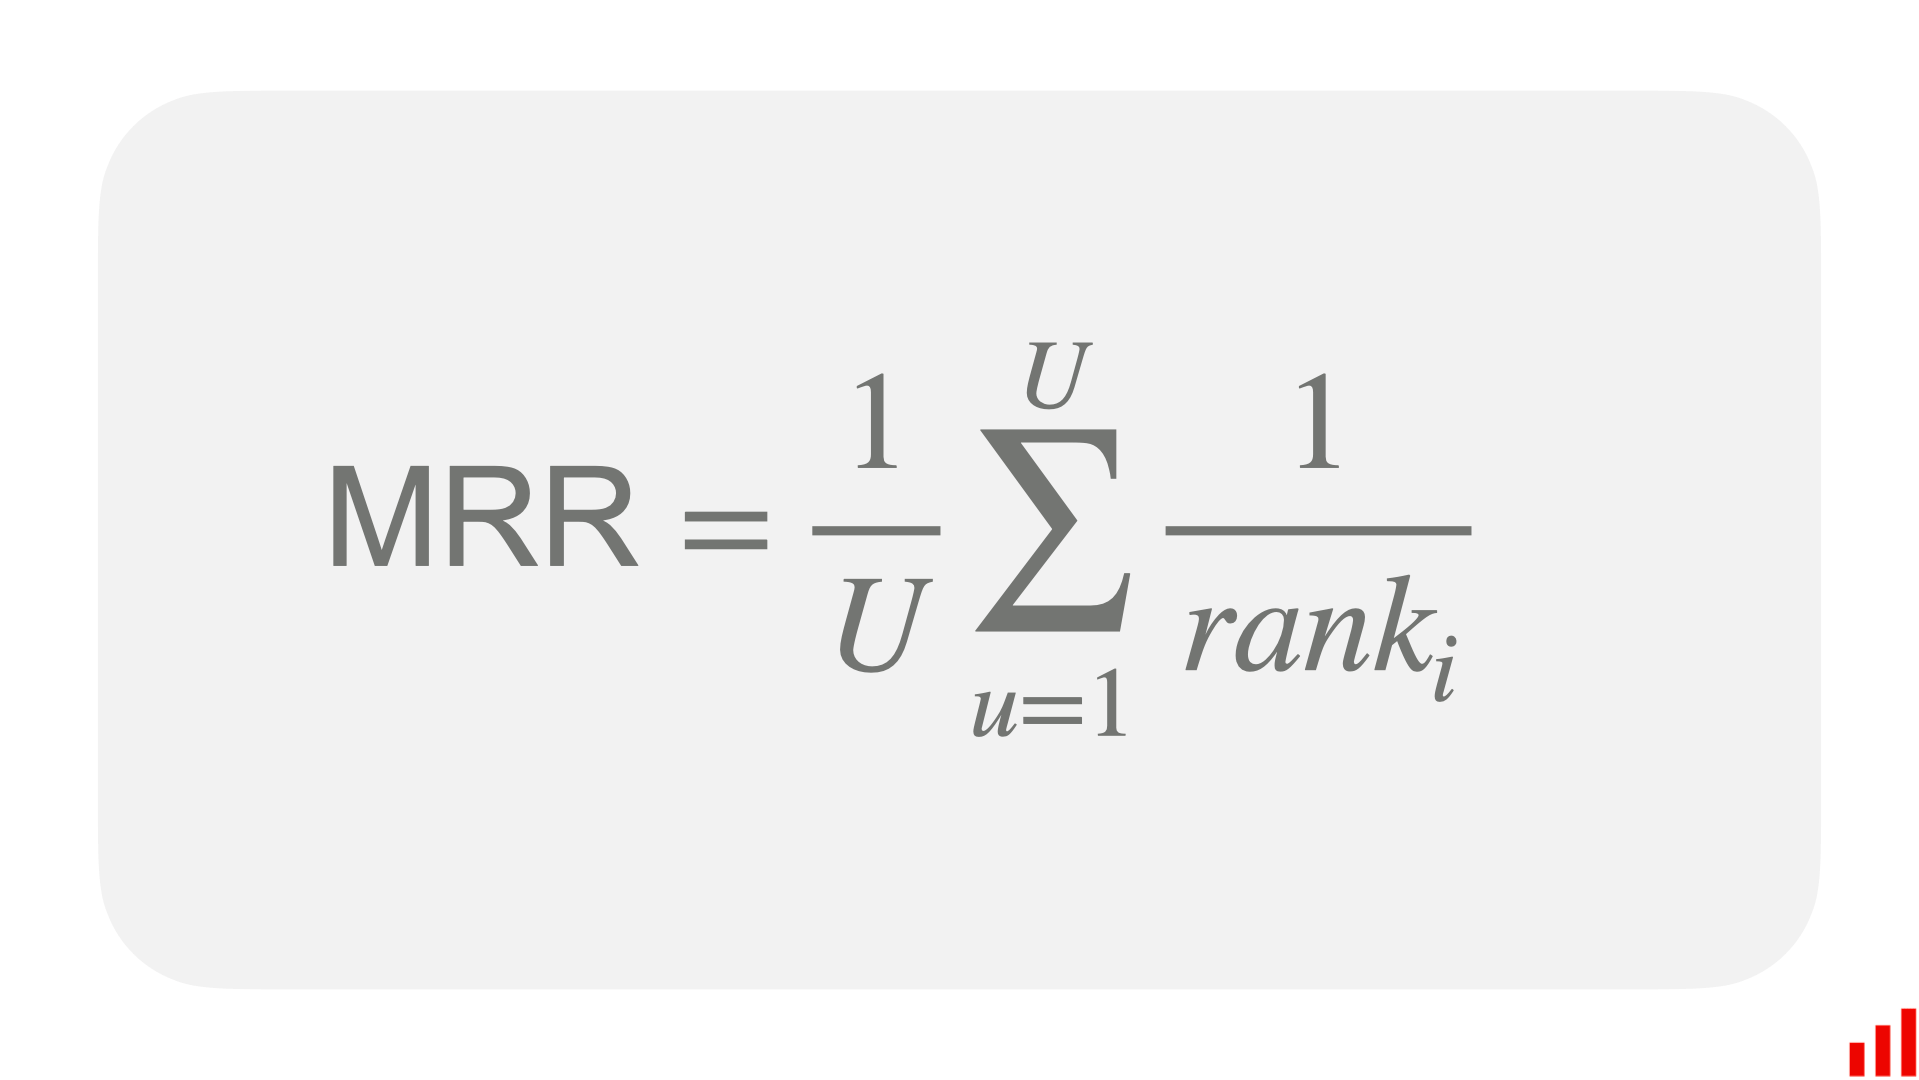

In [ ]:
ACG
DCG
NDCG